### PROJETO AVALIATIVO — MÓDULO 1
### Arquivo: `3_analise.ipynb` — Camada Gold
**Projeto:** Viagens a Serviço — Portal da Transparência  
**Arquitetura:** Raw → Silver → Gold

### Objetivo do notebook

Este notebook corresponde à Fase 3 do pipeline de dados. A partir das tabelas da camada **Silver**, preparadas no arquivo `2_transformar.py`, serão realizadas consultas SQL, análises de negócio e visualizações gráficas, além da construção da camada **Gold**, com tabelas e *views* agregadas.

As atividades desta etapa são:

1. Consultar e analisar os dados da camada Silver.
2. Criar a camada Gold, com tabelas e *views* para análises agregadas.
3. Responder às perguntas de negócio utilizando consultas SQL e tabelas.
4. Criar gráficos para facilitar a interpretação dos resultados.
5. Apresentar conclusões com base nos dados analisados.

### Atenção: ordem de execução

Antes de executar este notebook, certifique-se de que os seguintes arquivos foram executados:

- `0_criar_banco.sql` — criação da estrutura do banco de dados.
- `1_extrair.py` — extração e carga dos dados na camada Raw.
- `2_transformar.py` — limpeza, tratamento e carga dos dados na camada Silver.

Verifique também se o arquivo `.env` contém as configurações necessárias para a conexão com o PostgreSQL.

### Regras adotadas para as análises
Todas as perguntas de negócio consideram apenas as viagens com situação **Realizada** (`situacao = 'Realizada'`).  
Essa regra permite analisar os gastos e deslocamentos efetivamente realizados, desconsiderando viagens que não aconteceram.

### Organização das análises
As perguntas de negócio serão respondidas por meio de consultas SQL, tabelas, gráficos e conclusões. Parte das análises utilizará consultas diretas na camada Silver, enquanto outras utilizarão tabelas e *views* agregadas da camada Gold.

In [241]:
# ============================================================
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================================
import warnings
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
from PostgreSQL.banco import conectar

warnings.filterwarnings("ignore", message="pandas only supports SQLAlchemy")

In [242]:
# ============================================================
# 2. FUNÇÕES BÁSICAS
# ============================================================

# Exibir números com duas casas decimais
pd.set_option("display.float_format", "{:.2f}".format)

# Conecta ao Bando de Dados com SQL
def consultar_sql(sql):
    conexao = conectar()
    try:
        tabela = pd.read_sql(sql, conexao)
        return tabela
    finally:
        conexao.close()
    

# Formata números no padrão brasileiro
def formatar_numero(valor, casas=2):
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")

In [243]:
# ============================================================
# 3. TESTE DE CONEXÃO
# ============================================================
teste = consultar_sql("SELECT COUNT(*) AS viagens FROM silver_viagem")
print("Conexão OK. \nViagens na camada Silver:", teste["viagens"].iloc[0])

Conexão OK. 
Viagens na camada Silver: 341860


**PERGUNTA 1** - QUAIS SÃO OS 5 ÓRGÃOS COM MAIOR CUSTO TOTAL?  
O custo de uma viagem é a coluna 'valor_total' (somando: diárias + passagens + outros gastos − devolução). 

In [244]:
# Consulta SQL e criação Tabela Pergunta 1

tabela_1 = consultar_sql("""
    SELECT
        nome_orgao_superior AS "Órgão",
        SUM(valor_total) AS "Custo Total"
    FROM silver_viagem
    WHERE situacao = 'Realizada'
    GROUP BY nome_orgao_superior
    ORDER BY SUM(valor_total) DESC
    LIMIT 5
                           """)

tabela_1["Custo em Milhões"] = tabela_1["Custo Total"] /1_000_000
display(tabela_1)

,Órgão,Custo Total,Custo em Milhões
0,Ministério da Justiça e Segurança Pública,485748241.43,485.75
1,Ministério da Defesa,154595910.29,154.60
2,Ministério da Educação,109759836.03,109.76
3,Ministério do Meio Ambiente e Mudança do Clima,49300595.26,49.30
4,Ministério da Previdência Social,40236180.79,40.24


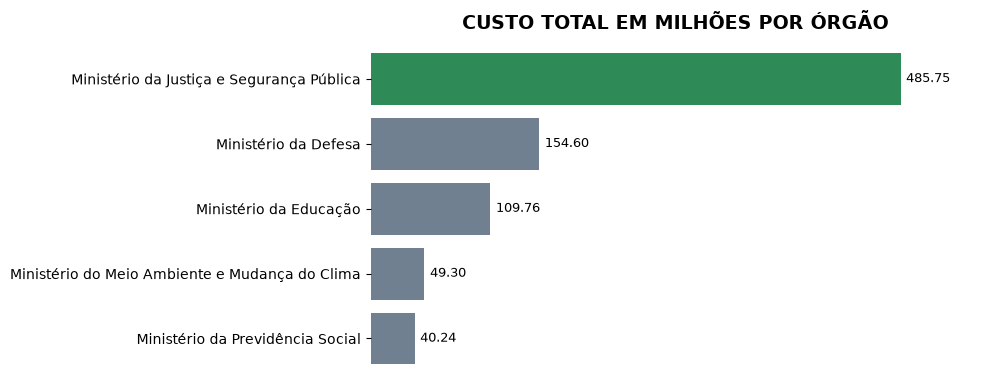

In [245]:
# Criação Gráfico Pergunta 1
fig, ax = plt.subplots(figsize=(10,4))
cores = ["seagreen"] + ["slategray"] * (len(tabela_1) - 1) # Destaca o primeiro órgão
barras = ax.barh(tabela_1["Órgão"],tabela_1["Custo em Milhões"],color=cores)
ax.bar_label(barras,fmt="%.2f",label_type="edge",padding=4,fontsize=9,color="black") # Custos logo após as barras
ax.set_title("CUSTO TOTAL EM MILHÕES POR ÓRGÃO",fontsize=14,fontweight="bold") # Título do gráfico
ax.invert_yaxis() # Mantem o primeiro órgão no topo
ax.set_xticks([]) # Retira os valores do eixo X
ax.margins(x=0.15) # Reserva espaço para os valores
for spine in ax.spines.values(): # Remover as linhas das bordas do gráfico
    spine.set_visible(False)

plt.savefig("Graficos/pergunta_1_custo_total_por_orgao.png",dpi=300,bbox_inches="tight")
plt.tight_layout()
plt.show()

In [246]:
# Conclusão Pergunta 1
print("=" * 65)
print("CONCLUSÃO ANALÍTICA - PERGUNTA 1")
print("=" * 65)

primeiro_orgao = tabela_1["Órgão"].iloc[0]
primeiro_custo = tabela_1["Custo em Milhões"].iloc[0]

segundo_orgao = tabela_1["Órgão"].iloc[1]
segundo_custo = tabela_1["Custo em Milhões"].iloc[1]
diferenca_percentual = ((primeiro_custo - segundo_custo) / segundo_custo) * 100

outros_quatro = tabela_1["Custo em Milhões"].iloc[1:].sum()
percentual_soma = (primeiro_custo / outros_quatro) * 100

print(f"O orgão com o maior custo total foi '{primeiro_orgao}'.")
print(f"Com o custo total de {primeiro_custo:.2f} milhões de reais.")

print(
    f"O custo foi {diferenca_percentual:.2f}% maior "
    f"que o do segundo colocado, '{segundo_orgao}'."
)

print(
    f"O custo do primeiro órgão equivale a "
    f"{percentual_soma:.2f}% da soma dos custos "
    f"dos outros quatro órgãos do ranking."
)

CONCLUSÃO ANALÍTICA - PERGUNTA 1
O orgão com o maior custo total foi 'Ministério da Justiça e Segurança Pública'.
Com o custo total de 485.75 milhões de reais.
O custo foi 214.21% maior que o do segundo colocado, 'Ministério da Defesa'.
O custo do primeiro órgão equivale a 137.26% da soma dos custos dos outros quatro órgãos do ranking.


**PERGUNTA 2** - QUAIS SÃO OS 3 DESTINOS COM MAIOR CUSTO MÉDIO POR VIAGEM?

In [247]:
# Consulta SQL e criação Tabela Pergunta 2
# Para afins de análise foram considerados apenas destinos que possuem mais que 100 viagens

tabela_2 = consultar_sql("""
    SELECT
        destinos AS "Destino",
        COUNT(id_viagem) AS "Qtd Viagens",
        AVG(valor_total) AS "Custo Médio"
    FROM silver_viagem
    WHERE situacao = 'Realizada'
    GROUP BY destinos
    HAVING COUNT(id_viagem) > 100
    ORDER BY AVG(valor_total) DESC
    LIMIT 3
                           """)
tabela_2["Custo em Milhares"] = tabela_2["Custo Médio"] /1_000
display(tabela_2)

,Destino,Qtd Viagens,Custo Médio,Custo em Milhares
0,"Brasília/DF, Brasília/DF",283,27401.80,27.40
1,Genebra/Suíça,242,25469.22,25.47
2,Nova York/Estados Unidos da América,149,21214.19,21.21


### Atenção — interpretação dos resultados

- **Agrupamento dos destinos:** a coluna `destinos` pode conter várias cidades ou trajetos em um único texto. Dessa forma, cada combinação textual diferente é considerada um destino distinto na consulta, e não necessariamente uma cidade individual.
- **Quantidade mínima de viagens:** foram considerados apenas registros com mais de 100 viagens realizadas por combinação de destinos. Esse critério reduz a influência de casos com poucas observações, que podem apresentar custos médios elevados.
- **Limitação da análise:** os resultados representam o custo médio das viagens agrupadas por texto de destino. Para analisar cada cidade individualmente, seria necessário tratar e separar os destinos antes do agrupamento.

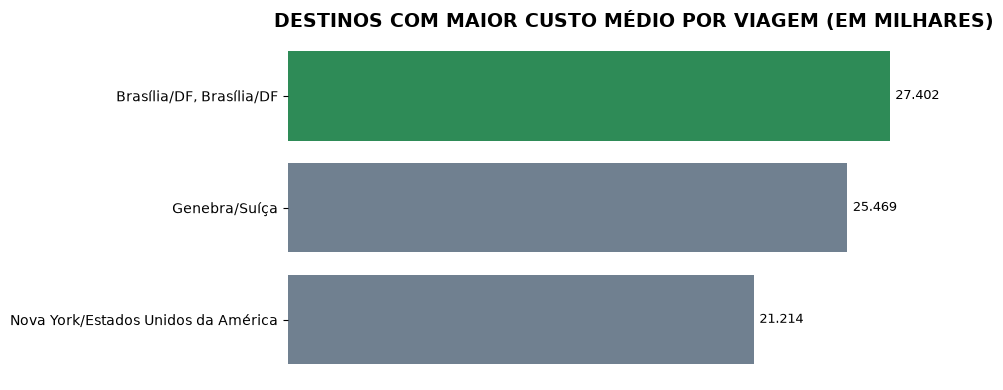

In [248]:
# Criação Gráfico Pergunta 2 
fig, ax = plt.subplots(figsize=(10,4))
cores = ["seagreen"] + ["slategray"] * (len(tabela_2) - 1) # Destaca o primeiro órgão
barras = ax.barh(tabela_2["Destino"],tabela_2["Custo em Milhares"],color=cores)
ax.bar_label(barras,fmt="%.3f",label_type="edge",padding=4,fontsize=9,color="black") # Custos logo após as barras
ax.set_title("DESTINOS COM MAIOR CUSTO MÉDIO POR VIAGEM (EM MILHARES)",fontsize=14,fontweight="bold") # Título do gráfico
ax.invert_yaxis() # Mantem o primeiro órgão no topo
ax.set_xticks([]) # Retira os valores do eixo X
ax.margins(x=0.15) # Reserva espaço para os valores
for spine in ax.spines.values(): # Remover as linhas das bordas do gráfico
    spine.set_visible(False)

plt.savefig("Graficos/pergunta_2_custo_medio_por_destino.png",dpi=300,bbox_inches="tight")
plt.tight_layout()
plt.show()

In [249]:
# Conclusão Pergunta 2
print("=" * 65)
print("CONCLUSÃO ANALÍTICA - PERGUNTA 2")
print("=" * 65)

primeiro_destino = tabela_2["Destino"].iloc[0]
primeiro_custo = tabela_2["Custo em Milhares"].iloc[0]
primeiro_qtd = tabela_2["Qtd Viagens"].iloc[0]

print(
    f"O destino com maior custo médio por viagem foi "
    f"'{primeiro_destino}', com custo médio de "
    f"R$ {primeiro_custo:.3f} mil."
)

print(
    f"Esse resultado considera {primeiro_qtd} viagens realizadas "
    f"para essa combinação de destinos."
)

print(
    "\nA análise considerou apenas destinos com mais de 100 viagens, "
    "reduzindo a influência de grupos com poucas observações."
)

print(
    "É importante observar que a coluna 'destinos' pode reunir várias cidades em um único texto." 
    "\nPortanto, o resultado representa uma combinação de destinos, e não necessariamente uma cidade individual."
)


CONCLUSÃO ANALÍTICA - PERGUNTA 2
O destino com maior custo médio por viagem foi 'Brasília/DF, Brasília/DF', com custo médio de R$ 27.402 mil.
Esse resultado considera 283 viagens realizadas para essa combinação de destinos.

A análise considerou apenas destinos com mais de 100 viagens, reduzindo a influência de grupos com poucas observações.
É importante observar que a coluna 'destinos' pode reunir várias cidades em um único texto.
Portanto, o resultado representa uma combinação de destinos, e não necessariamente uma cidade individual.


**PERGUNTA 3** - QUAL VIAGEM DE MAIOR DURAÇÃO E O SEU CUSTO TOTAL?

In [250]:
# Consulta SQL e criação Tabela Pergunta 3

tabela_3 = consultar_sql("""
    SELECT
        id_viagem AS "ID Viagem",
        nome_orgao_superior AS "Órgão",
        data_inicio AS "Data Início",
        data_fim AS "Data Fim",
        duracao_dias AS "Duração (dias)",
        valor_total AS "Custo Total"
    FROM silver_viagem
    WHERE situacao = 'Realizada' 
        AND duracao_dias IS NOT NULL
    ORDER BY duracao_dias DESC
    LIMIT 2    
                               """)
display(tabela_3)

,ID Viagem,Órgão,Data Início,Data Fim,Duração (dias),Custo Total
0,0000000000020699856,Ministério da Previdência Social,2025-01-13,2026-01-31,384,0.00
1,0000000000020793594,Ministério da Justiça e Segurança Pública,2025-01-02,2026-01-15,379,120650.00


### Atenção — interpretação dos resultados

A viagem com a maior duração registrada apresentou custo total igual a R$ 0,00. Com os dados disponíveis, não é possível determinar se esse valor decorre de uma falha de preenchimento ou se representa efetivamente uma viagem sem custos registrados.  
Por esse motivo, a analise foi realizada olhando as duas viagens com maior duração.

In [251]:
# Consulta SQL e criação da média da duração das outras viagens Pergunta 3

media_duracao = consultar_sql("""
    WITH viagens_classificadas AS (
        SELECT
            id_viagem,
            duracao_dias,
            ROW_NUMBER() OVER (
                ORDER BY duracao_dias DESC, id_viagem
            ) AS posicao
        FROM silver_viagem
        WHERE situacao = 'Realizada'
          AND duracao_dias IS NOT NULL
    )
    SELECT
        AVG(duracao_dias) AS "Média de Duração"
    FROM viagens_classificadas
    WHERE posicao > 2
""")

media_dias = media_duracao["Média de Duração"].iloc[0]

print(
    f"Média de duração das demais viagens: "
    f"{media_dias:.0f} dias"
)

Média de duração das demais viagens: 8 dias


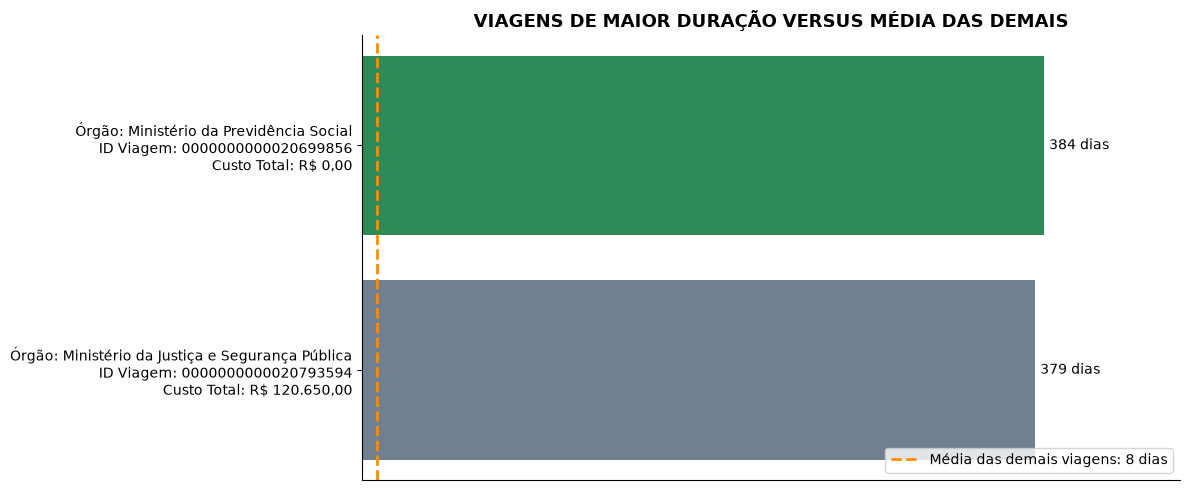

In [252]:
# Criação Gráfico Pergunta 3
rotulos = [
    f"Órgão: {orgao}\n"
    f"ID Viagem: {id_viagem}\n"
    f"Custo Total: R$ {formatar_numero(custo)}"
    for orgao, id_viagem, custo in zip(
        tabela_3["Órgão"],
        tabela_3["ID Viagem"],
        tabela_3["Custo Total"]
    )
]

duracoes = tabela_3["Duração (dias)"].tolist()
fig, ax = plt.subplots(figsize=(12, 5))
barras = ax.barh(rotulos,duracoes,color=["seagreen", "slategray"][:len(duracoes)])

# Linha de referência da média das demais viagens
ax.axvline(
    media_dias,
    color="darkorange",
    linestyle="--",
    linewidth=2,
    label=f"Média das demais viagens: {media_dias:.0f} dias"
)

# Identificação da duração e do custo
for barra, duracao in zip(barras,duracoes):
    ax.text(
        barra.get_width() + 3,
        barra.get_y() + barra.get_height() / 2,
        f"{duracao} dias",
        va="center",
        fontsize=10
    )

ax.set_title(
    "VIAGENS DE MAIOR DURAÇÃO VERSUS MÉDIA DAS DEMAIS",
    fontsize=13,
    fontweight="bold"
)

ax.invert_yaxis()
ax.legend(loc="lower right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.margins(x=0.20)
ax.set_xticks([]) # Retira os valores do eixo X

plt.savefig("Graficos/pergunta_3_duracao_viagens.png",dpi=300,bbox_inches="tight")
plt.tight_layout()
plt.show()

In [253]:
# Conclusão Pergunta 3
print("=" * 65)
print("CONCLUSÃO ANALÍTICA - PERGUNTA 3")
print("=" * 65)

for _, viagem in tabela_3.iterrows():
    duracao = viagem["Duração (dias)"]
    diferenca = duracao - media_dias
    multiplicador = duracao / media_dias

    print(
        f"A viagem de ID `{viagem['ID Viagem']}` teve duração "
        f"de {duracao} dias, {diferenca:.0f} dias acima "
        f"da média das demais viagens."
    )
    print(
        f"Sua duração corresponde a {multiplicador:.0f} "
        f"vezes a média de duração.\n"
    )
    
print(
    f"A duração média das demais viagens realizadas foi de "
    f"{media_dias:.0f} dias."
)


CONCLUSÃO ANALÍTICA - PERGUNTA 3
A viagem de ID `0000000000020699856` teve duração de 384 dias, 376 dias acima da média das demais viagens.
Sua duração corresponde a 47 vezes a média de duração.

A viagem de ID `0000000000020793594` teve duração de 379 dias, 371 dias acima da média das demais viagens.
Sua duração corresponde a 47 vezes a média de duração.

A duração média das demais viagens realizadas foi de 8 dias.


## CAMADA GOLD - AGREGAÇÕES PARA AS PERGUNTAS 4 A 7

Nesta etapa, serão criadas tabelas e views na camada Gold a partir das tabelas Silver.

As agregações utilizarão apenas viagens com situação `Realizada` e prepararão os dados para responder às perguntas de negócio 4 a 7.

As tabelas armazenam os resultados no momento da criação. As views executam suas consultas sobre os dados de origem a cada leitura.

Serão criados quatro conjuntos de agregações:

- **Gastos por órgão pagador:** quantidade de viagens, valor total pago e valor médio por pagamento.
- **Pagamentos por tipo:** quantidade de pagamentos, valor total e valor médio por tipo.
- **Trechos por meio de transporte:** quantidade de trechos por transporte.
- **Trechos por UF de destino:** quantidade de trechos por estado de destino.

In [270]:
# Criação das tabelas e views Gold

# Pergunta 4 - Pagamentos
sql_gold_pagamento = """
    SELECT
        p.tipo_pagamento,
        COUNT(*) AS qtd,
        ROUND(SUM(p.valor), 2) AS valor_total,
        ROUND(AVG(p.valor), 2) AS valor_medio
    FROM silver_pagamento p
    INNER JOIN silver_viagem v
        ON v.id_viagem = p.id_viagem
    WHERE v.situacao = 'Realizada'
    GROUP BY p.tipo_pagamento
"""

# Pergunta 5 - Transportes
sql_gold_trecho_por_transporte = """
    SELECT
        t.meio_transporte,
        COUNT(*) AS qtd_trechos
    FROM silver_trecho t
    INNER JOIN silver_viagem v
        ON v.id_viagem = t.id_viagem
    WHERE v.situacao = 'Realizada'
      AND t.meio_transporte IS NOT NULL
      AND TRIM(t.meio_transporte) <> ''
    GROUP BY t.meio_transporte
"""

# Pergunta 6 - UFs de destino
sql_gold_trecho_por_uf = """
    SELECT
        t.destino_uf,
        COUNT(*) AS qtd_trechos
    FROM silver_trecho t
    INNER JOIN silver_viagem v
        ON v.id_viagem = t.id_viagem
    WHERE v.situacao = 'Realizada'
      AND t.destino_uf IS NOT NULL
      AND TRIM(t.destino_uf) <> ''
    GROUP BY t.destino_uf
"""

# Pergunta 7 - Custo total por órgão
sql_gold_custo_orgao = """
    SELECT
        p.nome_orgao_pagador,
        COUNT(DISTINCT p.id_viagem) AS qtd_viagens,
        ROUND(SUM(p.valor), 2) AS valor_total_pago,
        ROUND(AVG(p.valor), 2) AS valor_medio_pago
    FROM silver_pagamento p
    INNER JOIN silver_viagem v
        ON v.id_viagem = p.id_viagem
    WHERE v.situacao = 'Realizada'
      AND p.nome_orgao_pagador IS NOT NULL
      AND TRIM(p.nome_orgao_pagador) <> ''
    GROUP BY p.nome_orgao_pagador
"""

conexao = conectar()

try:
    cursor = conexao.cursor()

    # Pergunta 4 - Tabela e view
    cursor.execute("DROP VIEW IF EXISTS vw_gold_pagamento_por_tipo")
    cursor.execute("DROP TABLE IF EXISTS gold_pagamento_por_tipo")
    cursor.execute("CREATE TABLE gold_pagamento_por_tipo AS "+ sql_gold_pagamento)
    cursor.execute("""
        CREATE VIEW vw_gold_pagamento_por_tipo AS
        SELECT *
        FROM gold_pagamento_por_tipo
    """)

    # Pergunta 5 - Tabela e view
    cursor.execute("DROP VIEW IF EXISTS vw_gold_trecho")
    cursor.execute("DROP TABLE IF EXISTS gold_trecho")
    cursor.execute("CREATE TABLE gold_trecho AS "+ sql_gold_trecho_por_transporte)
    cursor.execute("""
        CREATE VIEW vw_gold_trecho AS
        SELECT *
        FROM gold_trecho
    """)

    # Pergunta 6 - Tabela e view
    cursor.execute("DROP VIEW IF EXISTS vw_gold_trecho_por_uf")
    cursor.execute("DROP TABLE IF EXISTS gold_trecho_por_uf")
    cursor.execute("CREATE TABLE gold_trecho_por_uf AS "+ sql_gold_trecho_por_uf)
    cursor.execute("""
        CREATE VIEW vw_gold_trecho_por_uf AS
        SELECT *
        FROM gold_trecho_por_uf
    """)

    # Pergunta 7 - Tabela e view
    cursor.execute("DROP VIEW IF EXISTS vw_gold_custo_orgao")
    cursor.execute("DROP TABLE IF EXISTS gold_custo_orgao")
    cursor.execute("CREATE TABLE gold_custo_orgao AS " + sql_gold_custo_orgao)
    cursor.execute("""
        CREATE VIEW vw_gold_custo_orgao AS
        SELECT *
        FROM gold_custo_orgao
    """)
    
    conexao.commit()
    print("Gold das Perguntas 4, 5, 6 e 7 criadas: tabelas e views.")

except Exception as erro:
    conexao.rollback()
    print(
        "Erro ao criar as tabelas e views Gold:",
        type(erro).__name__,
        erro
    )

finally:
    conexao.close()

Gold das Perguntas 4, 5, 6 e 7 criadas: tabelas e views.


In [271]:
# Validação das tabelas e views Gold

# Pergunta 4 - Pagamentos
tabela_gold_pagamento = consultar_sql("""
    SELECT *
    FROM gold_pagamento_por_tipo
    ORDER BY tipo_pagamento
""")

view_gold_pagamento = consultar_sql("""
    SELECT *
    FROM vw_gold_pagamento_por_tipo
    ORDER BY tipo_pagamento
""")

print("PERGUNTA 4 - PAGAMENTOS")
print("Quantidade de linhas na tabela:", len(tabela_gold_pagamento))
print("Quantidade de linhas na view:", len(view_gold_pagamento))

if tabela_gold_pagamento.equals(view_gold_pagamento):
    print("Validação OK: tabela e view apresentam os mesmos dados.")
else:
    print("Atenção: existem diferenças entre a tabela e a view.")

print()

# Pergunta 5 - Transportes
tabela_gold_trecho = consultar_sql("""
    SELECT *
    FROM gold_trecho
    ORDER BY meio_transporte
""")

view_gold_trecho = consultar_sql("""
    SELECT *
    FROM vw_gold_trecho
    ORDER BY meio_transporte
""")

print("PERGUNTA 5 - TRANSPORTES")
print("Quantidade de linhas na tabela:", len(tabela_gold_trecho))
print("Quantidade de linhas na view:", len(view_gold_trecho))

if tabela_gold_trecho.equals(view_gold_trecho):
    print("Validação OK: tabela e view apresentam os mesmos dados.")
else:
    print("Atenção: existem diferenças entre a tabela e a view.")

print()

# Pergunta 6 - UFs de destino
tabela_gold_trecho_por_uf = consultar_sql("""
    SELECT *
    FROM gold_trecho_por_uf
    ORDER BY destino_uf
""")

view_gold_trecho_por_uf = consultar_sql("""
    SELECT *
    FROM vw_gold_trecho_por_uf
    ORDER BY destino_uf
""")

print("PERGUNTA 6 - UFs DE DESTINO")
print("Quantidade de linhas na tabela:", len(tabela_gold_trecho_por_uf))
print("Quantidade de linhas na view:", len(view_gold_trecho_por_uf))

if tabela_gold_trecho_por_uf.equals(view_gold_trecho_por_uf):
    print("Validação OK: tabela e view apresentam os mesmos dados.")
else:
    print("Atenção: existem diferenças entre a tabela e a view.")

print()

# Pergunta 7 - Custo por órgão
tabela_gold_custo_orgao = consultar_sql("""
    SELECT *
    FROM gold_custo_orgao
    ORDER BY nome_orgao_pagador
""")

view_gold_custo_orgao = consultar_sql("""
    SELECT *
    FROM vw_gold_custo_orgao
    ORDER BY nome_orgao_pagador
""")

print("PERGUNTA 7 - CUSTO POR ÓRGÃO")
print("Quantidade de linhas na tabela:", len(tabela_gold_custo_orgao))
print("Quantidade de linhas na view:", len(view_gold_custo_orgao))

if tabela_gold_custo_orgao.equals(view_gold_custo_orgao):
    print("Validação OK: tabela e view apresentam os mesmos dados.")
else:
    print("Atenção: existem diferenças entre a tabela e a view.")

PERGUNTA 4 - PAGAMENTOS
Quantidade de linhas na tabela: 4
Quantidade de linhas na view: 4
Validação OK: tabela e view apresentam os mesmos dados.

PERGUNTA 5 - TRANSPORTES
Quantidade de linhas na tabela: 8
Quantidade de linhas na view: 8
Validação OK: tabela e view apresentam os mesmos dados.

PERGUNTA 6 - UFs DE DESTINO
Quantidade de linhas na tabela: 28
Quantidade de linhas na view: 28
Validação OK: tabela e view apresentam os mesmos dados.

PERGUNTA 7 - CUSTO POR ÓRGÃO
Quantidade de linhas na tabela: 216
Quantidade de linhas na view: 216
Validação OK: tabela e view apresentam os mesmos dados.


**Pergunta 4** - Qual tipo de pagamento tem o maior valor médio?  
A análise utiliza a view `vw_gold_pagamento_por_tipo` para comparar a quantidade de pagamentos, o valor total pago e o valor médio por registro de pagamento em cada categoria.

In [256]:
# Criação tabela Pergunta 4
tabela_4 = consultar_sql("""
    SELECT
        tipo_pagamento,
        qtd,
        valor_total,
        valor_medio
    FROM vw_gold_pagamento_por_tipo
    ORDER BY valor_medio DESC;
""")
display(tabela_4)

,tipo_pagamento,qtd,valor_total,valor_medio
0,DIÁRIAS,400364,832271736.62,2078.79
1,PASSAGEM,182883,344243893.31,1882.32
2,Serviço correlato: seguro,4789,2141913.28,447.26
3,RESTITUIÇÃO,11574,2843762.01,245.70


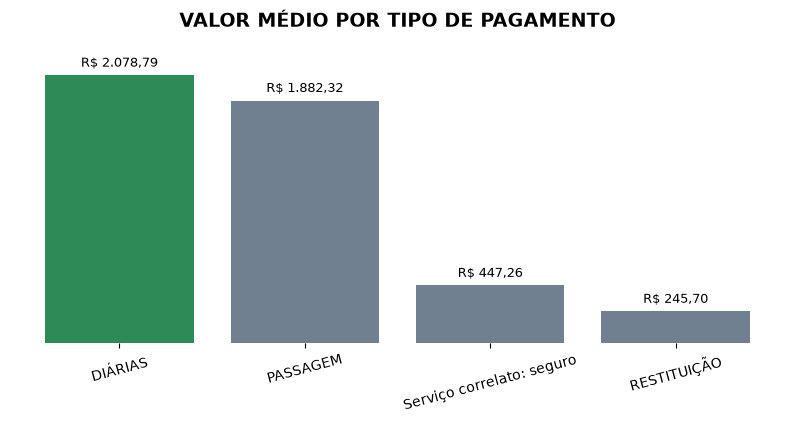

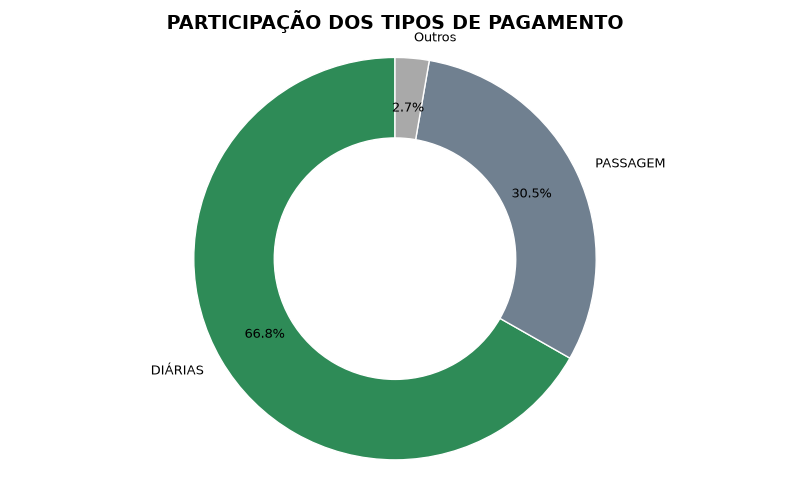

In [257]:
# Criação Gráfico Pergunta 4

ordem_tipos = ["DIÁRIAS","PASSAGEM","Serviço correlato: seguro","RESTITUIÇÃO"]

tabela_4["tipo_pagamento"] = pd.Categorical(
    tabela_4["tipo_pagamento"],
    categories=ordem_tipos,
    ordered=True
)

tabela_4 = tabela_4.sort_values("tipo_pagamento").copy()
fig, ax = plt.subplots(figsize=(10, 4))
cores = ["seagreen"] + ["slategray"] * (len(tabela_4) - 1)
barras = ax.bar(
    tabela_4["tipo_pagamento"],
    tabela_4["valor_medio"],
    color=cores
)

ax.bar_label(
    barras,
    labels=[
        f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
        for valor in tabela_4["valor_medio"]
    ],
    label_type="edge",
    padding=4,
    fontsize=9,
    color="black"
)

ax.set_title(
    "VALOR MÉDIO POR TIPO DE PAGAMENTO",
    fontsize=14,
    fontweight="bold"
)

ax.set_yticks([])
ax.tick_params(axis="x", labelrotation=15)
ax.margins(y=0.15)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.savefig(
    "Graficos/pergunta_4.1_valor_medio_por_tipo_pagamento.png",
    dpi=300,
    bbox_inches="tight"
)

# Criação Gráfico de Rosca Pergunta 4
# Agrupar os tipos de pagamento
tabela_rosca = tabela_4.copy()
tabela_rosca["tipo_pagamento"] = tabela_rosca["tipo_pagamento"].astype(str)
tabela_rosca["categoria"] = tabela_rosca["tipo_pagamento"].replace({
    "Serviço correlato: seguro": "Outros",
    "RESTITUIÇÃO": "Outros"
})
tabela_rosca = (tabela_rosca.groupby("categoria", as_index=False)["qtd"].sum())

# Definir a ordem das categorias
ordem_categorias = ["DIÁRIAS", "PASSAGEM", "Outros"]
tabela_rosca["categoria"] = pd.Categorical(
    tabela_rosca["categoria"],
    categories=ordem_categorias,
    ordered=True
)
tabela_rosca = tabela_rosca.sort_values("categoria")

# Criar gráfico
fig, ax = plt.subplots(figsize=(8, 5))
cores = ["seagreen", "slategray", "darkgray"]
fatias, textos, percentuais = ax.pie(
    tabela_rosca["qtd"],
    labels=tabela_rosca["categoria"],
    colors=cores,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.75,
    wedgeprops={"width": 0.4, "edgecolor": "white"},
    textprops={"fontsize": 9}
)
ax.set_title(
    "PARTICIPAÇÃO DOS TIPOS DE PAGAMENTO",
    fontsize=14,
    fontweight="bold"
)

for percentual in percentuais:
    percentual.set_color("black")
    percentual.set_fontsize(9)

ax.axis("equal")

plt.savefig(
    "Graficos/pergunta_4.2_participacao_por_tipo_pagamento.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()



In [266]:
# Conclusão Pergunta 4

def formatar_percentual(valor):
    return f"{valor:.2f}%".replace(".", ",")

print("=" * 65)
print("CONCLUSÃO ANALÍTICA - PERGUNTA 4")
print("=" * 65)

print(
    f"A principal forma de pagamento é: {maior_media['categoria']}, "
    f"com o valor médio de {moeda(maior_media['valor_medio'])}."
)

print(
    f"Maior quantidade de pagamentos: {maior_quantidade['categoria']}, "
    f"com {formatar_percentual(maior_quantidade['participacao_qtd'])} "
    f"dos registros."
)

print(
    f"Maior participação no valor financeiro total: "
    f"{maior_valor_total['categoria']}, com "
    f"{formatar_percentual(maior_valor_total['participacao_valor'])}."
)

CONCLUSÃO ANALÍTICA - PERGUNTA 4
A principal forma de pagamento é: DIÁRIAS, com o valor médio de R$ 2.078,79.
Maior quantidade de pagamentos: DIÁRIAS, com 66,77% dos registros.
Maior participação no valor financeiro total: DIÁRIAS, com 70,44%.


**PERGUNTA 5** - QUAIS SÃO OS MEIOS DE TRANSPORTES MAIS UTILIZADO?  
A análise utiliza a view `vw_gold_trecho` para comparar a quantidade de viagens para cada meio de transporte.

In [259]:
# Consulta da Pergunta 5
tabela_5 = consultar_sql("""
    SELECT
        meio_transporte AS "Meio de Transporte",
        qtd_trechos AS "Quantidade"
    FROM vw_gold_trecho
    ORDER BY qtd_trechos DESC;
""")
tabela_5["Quantidade"] = tabela_5["Quantidade"].map(
    lambda valor: f"{valor:,.0f}".replace(",", ".")
)
display(tabela_5)

,Meio de Transporte,Quantidade
0,Veículo Oficial,385.734
1,Aéreo,226.707
2,Rodoviário,64.454
3,Veículo Próprio,42.736
4,Inválido,26.523
5,Fluvial,8.392
6,Ferroviário,868
7,Marítimo,471


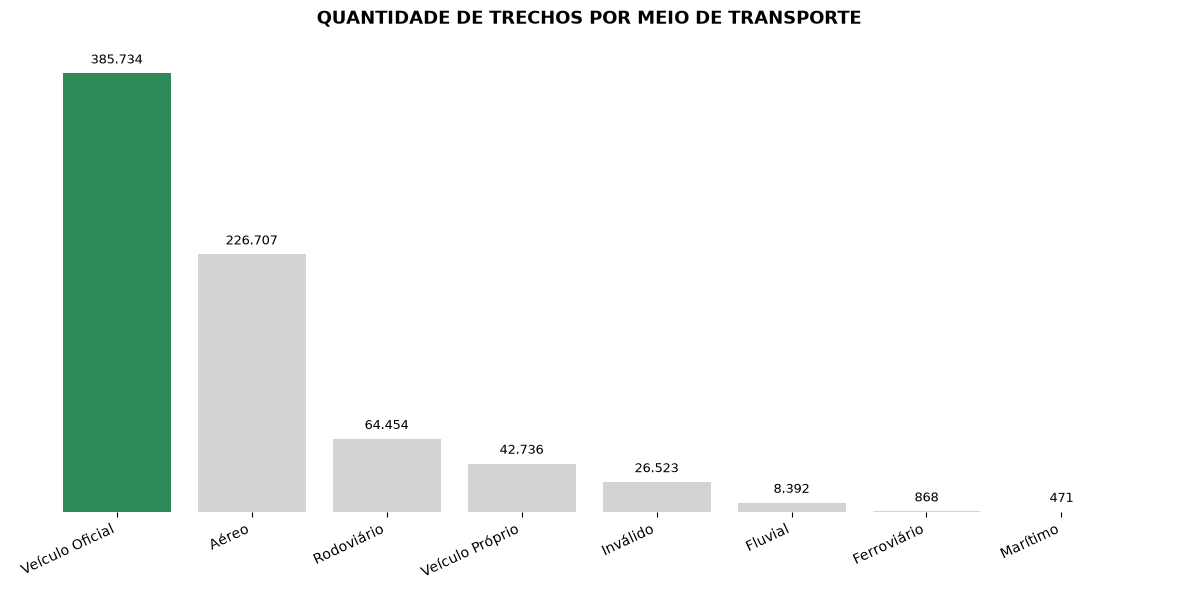

In [260]:
# Gráfico - Pergunta 5
# Cópia dos dados para preservar a tabela original
grafico_5 = tabela_5.copy()

# Garantir que a quantidade seja numérica
grafico_5["Quantidade"] = (
    grafico_5["Quantidade"]
    .astype(str)
    .str.replace(".", "", regex=False)
    .astype(int)
)

# Ordenar do mais utilizado para o menos utilizado
grafico_5 = grafico_5.sort_values(
    by="Quantidade",
    ascending=False
)

fig, ax = plt.subplots(figsize=(12, 6))

cores = [
    "seagreen" if i == 0 else "lightgray"
    for i in range(len(grafico_5))
]

barras = ax.bar(
    grafico_5["Meio de Transporte"],
    grafico_5["Quantidade"],
    color=cores
)

# Valores acima das barras
for barra in barras:
    valor = int(barra.get_height())

    ax.annotate(
        f"{valor:,}".replace(",", "."),
        (barra.get_x() + barra.get_width() / 2, valor),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Título e formatação
ax.set_title(
    "QUANTIDADE DE TRECHOS POR MEIO DE TRANSPORTE",
    fontsize=13,
    fontweight="bold",
    pad=20
)

ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(
        lambda valor, pos: f"{valor:,.0f}".replace(",", ".")
    )
)

# Remover bordas dos eixos
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)

ax.tick_params(axis="y", length=0)
plt.xticks(rotation=25, ha="right")
ax.set_yticks([])
plt.tight_layout()

# Salvar o gráfico
plt.savefig(
    "Graficos/pergunta_5_quantidade_por_meio_transporte.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [261]:
# Conclusão analítica - Pergunta 5

# Ordenar os meios de transporte pela quantidade de trechos
resumo_5 = tabela_5.copy()

resumo_5["Quantidade"] = (
    resumo_5["Quantidade"]
    .astype(str)
    .str.replace(".", "", regex=False)
    .astype(int)
)

resumo_5 = resumo_5.sort_values(
    by="Quantidade",
    ascending=False
).reset_index(drop=True)

# Identificar os resultados do ranking
primeiro = resumo_5.iloc[0]
segundo = resumo_5.iloc[1]

nome_primeiro = primeiro["Meio de Transporte"]
qtd_primeiro = primeiro["Quantidade"]

nome_segundo = segundo["Meio de Transporte"]
qtd_segundo = segundo["Quantidade"]

# Comparação percentual com o segundo colocado
diferenca_segundo = (
    (qtd_primeiro / qtd_segundo) - 1
) * 100

# Comparação com a soma dos demais meios de transporte
soma_demais = resumo_5.iloc[1:]["Quantidade"].sum()

percentual_demais = (
    qtd_primeiro / soma_demais
) * 100

print("=" * 64)
print("CONCLUSÃO ANALÍTICA - PERGUNTA 5")
print("=" * 64)

print(
    f"O meio de transporte com a maior quantidade de trechos foi "
    f"'{nome_primeiro}'."
)

print(
    f"Com um total de {qtd_primeiro:,.0f} trechos."
    .replace(",", ".")
)

print(
    f"A quantidade foi {diferenca_segundo:.2f}% maior que a do "
    f"segundo colocado, '{nome_segundo}'."
)

print(
    f"A quantidade do primeiro colocado equivale a "
    f"{percentual_demais:.2f}% da soma das quantidades dos "
    f"outros {len(resumo_5) - 1} meios de transporte do ranking."
)

CONCLUSÃO ANALÍTICA - PERGUNTA 5
O meio de transporte com a maior quantidade de trechos foi 'Veículo Oficial'.
Com um total de 385.734 trechos.
A quantidade foi 70.15% maior que a do segundo colocado, 'Aéreo'.
A quantidade do primeiro colocado equivale a 104.21% da soma das quantidades dos outros 7 meios de transporte do ranking.


**PERGUNTA 6** - QUAIS UF's DE DESTINO APARECEM EM MAIS TRECHOS?
A análise utiliza a view `vw_gold_trecho_por_uf` para comparar a quantidade de viagens para cada UF.

In [262]:
# Consulta da Pergunta 5
tabela_6 = consultar_sql("""
    SELECT
        destino_uf AS "Destino",
        qtd_trechos AS "Quantidade"
    FROM vw_gold_trecho_por_uf
    ORDER BY qtd_trechos DESC;
""")
tabela_6["Quantidade"] = tabela_6["Quantidade"].map(
    lambda valor: f"{valor:,.0f}".replace(",", ".")
)
display(tabela_6)

,Destino,Quantidade
0,São Paulo,81.727
1,Distrito Federal,77.962
2,Minas Gerais,50.555
3,Rio de Janeiro,43.481
4,Paraná,42.323
5,Pará,39.742
6,Rio Grande do Sul,38.397
7,Mato Grosso do Sul,30.450
8,Bahia,28.141
9,Pernambuco,28.117


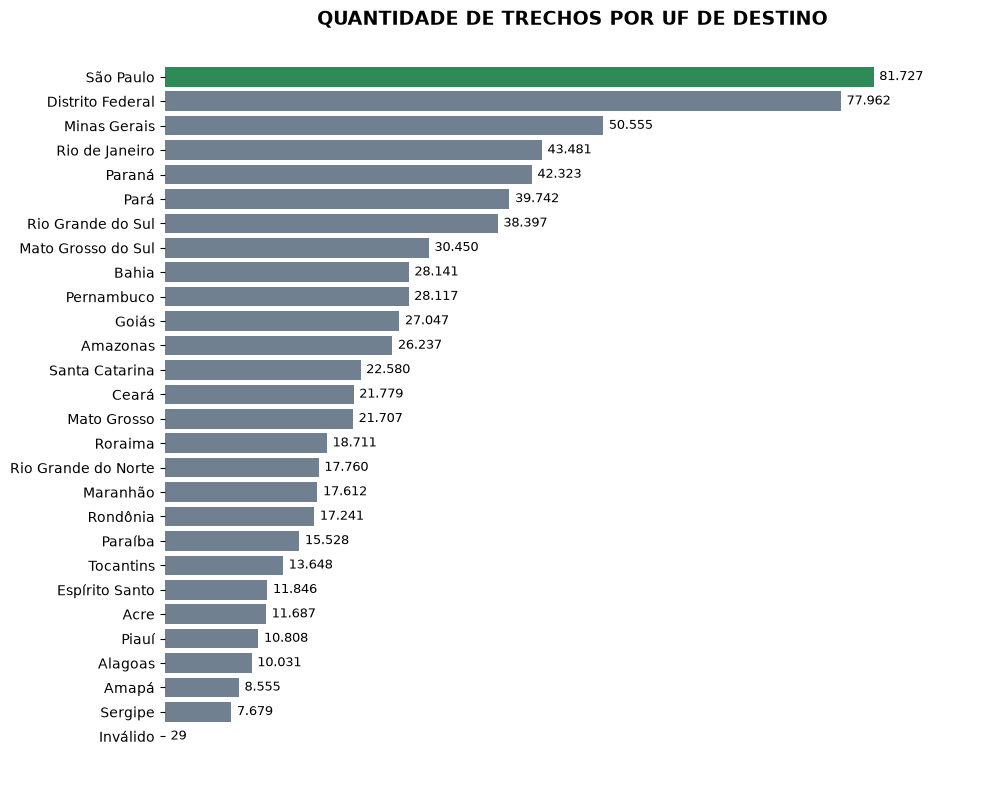

In [263]:
# Criação Gráfico Pergunta 6
fig, ax = plt.subplots(figsize=(10, 8))
cores = ["seagreen"] + ["slategray"] * (len(tabela_6) - 1) # Destaca o primeiro destino
barras = ax.barh(
    tabela_6["Destino"],
    tabela_6["Quantidade"].astype(str).str.replace(".", "", regex=False).astype(int),
    color=cores
)
ax.bar_label(
    barras,
    fmt="%.0f",
    labels=[
        f"{valor:,.0f}".replace(",", ".")
        for valor in tabela_6["Quantidade"].astype(str).str.replace(".", "", regex=False).astype(int)
    ],
    label_type="edge",
    padding=4,
    fontsize=9,
    color="black"
) # Quantidades logo após as barras

ax.set_title(
    "QUANTIDADE DE TRECHOS POR UF DE DESTINO",
    fontsize=14,
    fontweight="bold"
) # Título do gráfico
ax.invert_yaxis() # Mantém o destino com mais trechos no topo
ax.set_xticks([]) # Retira os valores do eixo X
ax.margins(x=0.15) # Reserva espaço para os valores
for spine in ax.spines.values(): # Remove as linhas das bordas do gráfico
    spine.set_visible(False)
plt.savefig(
    "Graficos/pergunta_6_quantidade_por_uf_destino.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()

In [264]:
# Conclusão analítica - Pergunta 6

# Preparar os dados para os cálculos
resumo_6 = tabela_6.copy()

resumo_6["Quantidade"] = (
    resumo_6["Quantidade"]
    .astype(str)
    .str.replace(".", "", regex=False)
    .astype(int)
)

resumo_6 = resumo_6.sort_values(
    by="Quantidade",
    ascending=False
).reset_index(drop=True)

# Identificar os dois primeiros destinos
primeiro = resumo_6.iloc[0]
segundo = resumo_6.iloc[1]

nome_primeiro = primeiro["Destino"]
qtd_primeiro = primeiro["Quantidade"]

nome_segundo = segundo["Destino"]
qtd_segundo = segundo["Quantidade"]

# Diferença percentual em relação ao segundo colocado
diferenca_segundo = (
    (qtd_primeiro / qtd_segundo) - 1
) * 100

# Soma das quantidades dos demais destinos
soma_demais = resumo_6.iloc[1:]["Quantidade"].sum()

# Comparação com os demais destinos
percentual_demais = (
    qtd_primeiro / soma_demais
) * 100

print("=" * 65)
print("CONCLUSÃO ANALÍTICA - PERGUNTA 6")
print("=" * 65)

print(
    f"O destino com a maior quantidade de trechos foi "
    f"'{nome_primeiro}'."
)

print(
    f"Com um total de {qtd_primeiro:,.0f} trechos."
    .replace(",", ".")
)

print(
    f"A quantidade foi {diferenca_segundo:.2f}% maior que a do "
    f"segundo colocado, '{nome_segundo}'."
)

print(
    f"A quantidade do primeiro destino equivale a "
    f"{percentual_demais:.2f}% da soma das quantidades dos outros "
    f"{len(resumo_6) - 1} destinos do ranking."
)

CONCLUSÃO ANALÍTICA - PERGUNTA 6
O destino com a maior quantidade de trechos foi 'São Paulo'.
Com um total de 81.727 trechos.
A quantidade foi 4.83% maior que a do segundo colocado, 'Distrito Federal'.
A quantidade do primeiro destino equivale a 12.39% da soma das quantidades dos outros 27 destinos do ranking.


**PERGUNTA 7** - QUAL ORGÃO PAGOU MAIS NO TOTAL?

In [282]:
# Consulta da Pergunta 7 - Custo total por órgão

tabela_7 = consultar_sql("""
    SELECT
        nome_orgao_pagador AS "Órgão",
        valor_total_pago AS "Custo Total"
    FROM vw_gold_custo_orgao
    ORDER BY valor_total_pago DESC
    LIMIT 10;
""")

# Converter o custo total para milhões
tabela_7["Total Milhões"] = tabela_7["Custo Total"] / 1_000_000

# Formatar os valores em reais
tabela_7["Custo Total"] = tabela_7["Custo Total"].map(
    lambda valor: f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
)

tabela_7["Total Milhões"] = tabela_7["Total Milhões"].map(
    lambda valor: f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
)

display(tabela_7)

,Órgão,Custo Total,Total Milhões
0,Fundo Nacional de Segurança Pública,"R$ 278.288.685,42","R$ 278,29"
1,Sigiloso,"R$ 199.308.482,09","R$ 199,31"
2,Comando da Aeronáutica,"R$ 81.069.602,67","R$ 81,07"
3,Instituto Nacional do Seguro Social,"R$ 37.254.697,89","R$ 37,25"
4,Comando do Exército,"R$ 36.576.135,70","R$ 36,58"
5,Ministério da Gestão e da Inovação em Serviços...,"R$ 34.464.632,12","R$ 34,46"
6,Instituto Brasileiro do Meio Ambiente e dos Re...,"R$ 31.395.742,54","R$ 31,40"
7,Ministério das Relações Exteriores - Unidades ...,"R$ 24.939.840,86","R$ 24,94"
8,Receita Federal do Brasil,"R$ 23.474.664,79","R$ 23,47"
9,Ministério da Agricultura e Pecuária - Unidade...,"R$ 22.497.534,01","R$ 22,50"


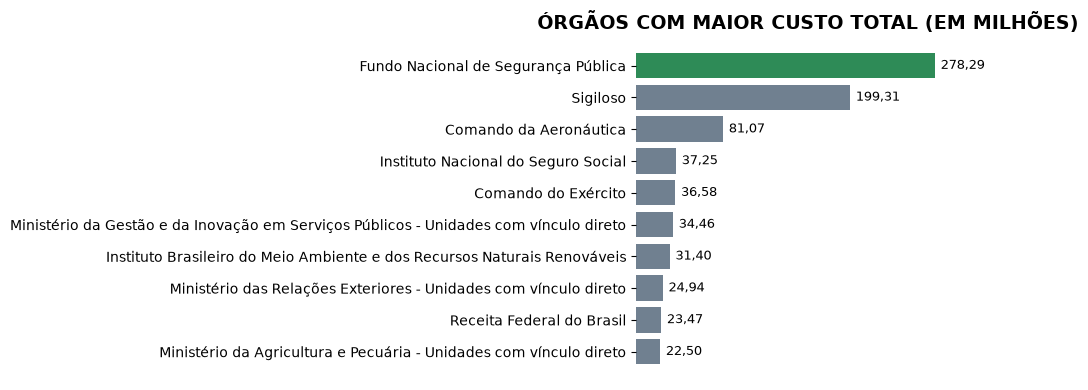

In [288]:
# Criação Gráfico Pergunta 7

# Converter os valores formatados em números para o gráfico
grafico_7 = tabela_7.copy()

grafico_7["Total Milhões"] = (
    grafico_7["Total Milhões"]
    .astype(str)
    .str.replace("R$", "", regex=False)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip()
    .astype(float)
)

fig, ax = plt.subplots(figsize=(10, 4))

cores = ["seagreen"] + ["slategray"] * (len(grafico_7) - 1) # Destaca o primeiro órgão

barras = ax.barh(
    grafico_7["Órgão"],
    grafico_7["Total Milhões"],
    color=cores
)

ax.bar_label(
    barras,
    labels=[
        f"{valor:.2f}".replace(".", ",")
        for valor in grafico_7["Total Milhões"]
    ],
    label_type="edge",
    padding=4,
    fontsize=9,
    color="black"
) # Valores em milhões logo após as barras

ax.set_title(
    "ÓRGÃOS COM MAIOR CUSTO TOTAL (EM MILHÕES)",
    fontsize=14,
    fontweight="bold"
) # Título do gráfico

ax.invert_yaxis() # Mantém o órgão com maior custo no topo
ax.set_xticks([]) # Retira os valores do eixo X
ax.margins(x=0.15) # Reserva espaço para os valores

for spine in ax.spines.values(): # Remove as linhas das bordas do gráfico
    spine.set_visible(False)

plt.savefig(
    "Graficos/pergunta_7_custo_total_por_orgao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()

In [289]:
# Conclusão Pergunta 7

# Consultar os valores numéricos dos órgãos
resumo_7 = consultar_sql("""
    SELECT
        nome_orgao_pagador AS orgao,
        valor_total_pago
    FROM vw_gold_custo_orgao
    ORDER BY valor_total_pago DESC
""")

# Identificar o primeiro e o segundo colocados
maior_custo = resumo_7.iloc[0]
segundo_custo = resumo_7.iloc[1]

# Calcular a diferença percentual em relação ao segundo colocado
diferenca_segundo = (
    (maior_custo["valor_total_pago"] / segundo_custo["valor_total_pago"]) - 1
) * 100

# Calcular a participação do primeiro órgão em relação aos demais
soma_demais = resumo_7.iloc[1:]["valor_total_pago"].sum()

participacao_demais = (
    maior_custo["valor_total_pago"] / soma_demais
) * 100

# Funções de formatação
def moeda(valor):
    return f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

def formatar_percentual(valor):
    return f"{valor:.2f}%".replace(".", ",")

print("=" * 65)
print("CONCLUSÃO ANALÍTICA - PERGUNTA 7")
print("=" * 65)

print(
    f"O órgão que mais pagou foi: {maior_custo['orgao']}, "
    f"com um custo total de {moeda(maior_custo['valor_total_pago'])}."
)

print(
    f"O valor foi {formatar_percentual(diferenca_segundo)} maior "
    f"que o do segundo colocado, {segundo_custo['orgao']}."
)

print(
    f"O custo do primeiro órgão equivale a "
    f"{formatar_percentual(participacao_demais)} da soma dos custos "
    f"dos outros {len(resumo_7) - 1} órgãos."
)

CONCLUSÃO ANALÍTICA - PERGUNTA 7
O órgão que mais pagou foi: Fundo Nacional de Segurança Pública, com um custo total de R$ 278.288.685,42.
O valor foi 39,63% maior que o do segundo colocado, Sigiloso.
O custo do primeiro órgão equivale a 30,81% da soma dos custos dos outros 215 órgãos.


### PERGUNTAS EXTRAS
**PERGUNTA 1** - QUAL VIAJANTE PAGOU MAIS NO TOTAL? QUAL A QUANTIDADE DE VIAGEM E A MÉDIA POR VIAGEM?  
**PERGUNTA 2** - QUAL O CUSTO TOTAL DAS VIAGENS POR MÊS?  
**PERGUNTA 3** - QUAIS ORGÃOS REALIZARAM MAIS VIAGENS, POR MÊS?  
**PERGUNTA 4** - QUAL O CUSTO MÉDIO POR VIAGEM DE CADA ORGÃO?  
**PERGUNTA 5** - QUAL A QUANTIDADE DE TECHOS POR VIAGEM E A MÉDIA?  
**PERGUNTA 6** - QUAL A QUANTIDADE E CUSTO TOTAL PARA VIAGENS NACIONAS E INTERNACIONAIS?  

### Andamento da análise

As sete perguntas de negócio obrigatórias foram concluídas no notebook `3_analise.ipynb`. As análises utilizam consultas SQL sobre a camada Gold, construída a partir dos dados tratados na camada Silver, e apresentam resultados em tabelas, gráficos e conclusões analíticas.

As consultas consideram apenas viagens com situação **`Realizada`**, conforme a regra de negócio definida para o projeto.

| Pergunta | Análise realizada | Visualização |
|---|---|---|
| 1 | Cinco órgãos com maior custo total de viagens | `pergunta_1_custo_total_por_orgao.png` |
| 2 | Três combinações de destinos com maior custo médio por viagem, considerando apenas grupos com mais de 100 viagens realizadas | `pergunta_2_custo_medio_por_destino.png` |
| 3 | Duas viagens de maior duração, comparadas à duração média das demais viagens realizadas | `pergunta_3_duracao_viagens.png` |
| 4 | Comparação dos tipos de pagamento por quantidade, valor total e valor médio, identificando o tipo com maior valor médio | `pergunta_4_valor_medio_por_tipo_pagamento.png` |
| 5 | Quantidade de trechos por meio de transporte, identificando os mais utilizados | `pergunta_5_quantidade_por_meio_transporte.png` |
| 6 | Quantidade de trechos por UF de destino, identificando os destinos com maior ocorrência | `pergunta_6_quantidade_por_uf_destino.png` |
| 7 | Dez órgãos com maior custo total de pagamentos | `pergunta_7_custo_total_por_orgao.png` |

**Observações metodológicas**

- **Pergunta 2:** a coluna `destinos` pode conter várias cidades em um mesmo texto. Portanto, o agrupamento representa combinações textuais de destinos, não necessariamente cidades individuais.
- **Pergunta 3:** a viagem de maior duração apresentou custo total igual a zero, enquanto a segunda apresentou custo de R$ 120.650,00. O valor zero foi sinalizado como ponto de atenção, sem presumir que seja um erro de preenchimento.
- **Pergunta 4:** o valor médio é calculado por registro de pagamento. A quantidade de pagamentos e o valor financeiro total também são utilizados para comparar os tipos de pagamento.
- **Perguntas 5 e 6:** as contagens consideram os trechos associados às viagens realizadas. Categorias presentes nos dados, como `Inválido`, são mantidas quando não foram excluídas explicitamente pelas consultas.
- **Pergunta 7:** o ranking considera os dez órgãos com maior valor total pago. A soma é calculada a partir dos registros de pagamento associados às viagens realizadas.

**Validação da camada Gold**

Foram criadas tabelas e views para as perguntas 4 a 7. A validação compara os resultados de cada tabela com sua respectiva view, verificando a quantidade de linhas e a igualdade dos dados.

**Status:** as sete perguntas obrigatórias foram concluídas, com consultas SQL, tabelas de resultados, visualizações e conclusões analíticas. Os gráficos são salvos no diretório `Graficos/`.